# simple_spread: the paradigms on a standard cooperative task

After the probes (`probe_paradigms.ipynb`), a second test of the RL layer, on a task
that is not ours: Farama's MPE2 `simple_spread`
([docs](https://mpe2.farama.org/mpe/simple_spread/)), with **continuous actions**.
It is small enough to train in minutes and to watch, and every training paradigm
(DTDE, CTCE, CTDE) and algorithm (PPO, APPO, SAC) can run on it, so this notebook
trains the full 3 x 3 matrix and shows what the agents learned.

What this tests, and what it does not: the probes check single pieces against exact
answers; here the answer is only "better than random". A cell that stays at the
random level does not say which piece is broken; it says where to look, with the
probes and the learner's health metrics (entropy, KL, NaN losses). **Nothing in
`core/rl/` is changed**; the algorithms keep the original settings except the
learning rate and the batch size, as in the probes.

Needs `pip install mpe2` in the `marlem` environment (done once; it adds
PettingZoo and pygame-ce).

**Start small.** With `QUICK = True` (the default) every combination trains for a
few iterations only: about 5 minutes for the whole notebook, enough to see that
everything runs and to read the first numbers. `RUN` picks which combinations to
train. For the real run set `QUICK = False`: roughly 30 to 45 minutes for the full
matrix (see `ITERS`). Close other programs first: each run loads torch and Ray in
this process.

In [1]:
import math
import os
import sys
import time
from io import BytesIO
from pathlib import Path

# RL root; imports use its parent so market core/ stays separate.
ROOT = next(p / "RL" for p in [Path.cwd(), *Path.cwd().parents] if (p / "RL" / "core").is_dir())
sys.path.insert(0, str(ROOT.parent))
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(ROOT.parent), os.environ.get("PYTHONPATH", "")]))  # Ray's worker processes import RL.core too

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as GifImage, display
from PIL import Image, ImageDraw

from RL.core.envs.spread import SimpleSpread, baseline_return, episode_frames, random_policy
from RL.core.rl.base import RLAlgorithm, TrainingMode
from RL.core.rl.local import build_local, train
from RL.core.rl.probe import mean_actions
from RL.core.rl.train import RLTrainer

pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)

ENV_CONFIG = {"n_agents": 3, "max_cycles": 25, "local_ratio": 0.5}

ALGORITHMS = [RLAlgorithm.PPO, RLAlgorithm.APPO, RLAlgorithm.SAC]
MODES = [TrainingMode.DTDE, TrainingMode.CTCE, TrainingMode.CTDE]

# True: a few iterations per combination, to check that everything runs (~5 min).
# False: the budget in ITERS below (~30-45 min for the full matrix).
QUICK = True

# Which combinations to train, as (algorithm, paradigm); None trains all nine.
# For example: RUN = [("PPO", "dtde"), ("PPO", "ctde")]
RUN = None

# Iterations per algorithm. One RLlib iteration is a different amount of
# experience for each (measured here: PPO 1,000 environment steps, APPO about
# 3,100, SAC about 340), so these are chosen for roughly the same experience,
# 60,000 to 70,000 steps, and the same time. Raise them to train longer.
ITERS = {"PPO": 60, "APPO": 20, "SAC": 200}
if QUICK:
    ITERS = {"PPO": 3, "APPO": 4, "SAC": 10}  # APPO and SAC learn only after the first samples

# lr 3e-4 is the usual setting; the original starts at 1e-5 and lets
# population-based training raise it. PPO's batch is 1,000 steps (the original's
# default is 4,000), as in the probes. Everything else is the original's.
TRAINING = {
    "PPO": {"lr": 3e-4, "train_batch_size_per_learner": 1000},
    "APPO": {"lr": 3e-4},
    "SAC": {"actor_lr": 3e-4, "critic_lr": 3e-4},
}

BASELINE_EPISODES = 200
EVAL_EPISODES = 3 if QUICK else 20  # episodes for the mean-action return
SEED = 0  # episode drawn in the GIFs
EVAL_SEED = 1000  # first seed of the evaluation episodes (trained and baselines)

## a. The environment

Three agents and three landmarks in a plane; the agents should cover the landmarks,
one each, without bumping into each other. An episode lasts 25 steps.

- **Observation** (18 numbers per agent): own velocity (2), own position (2), the
  landmarks' positions relative to the agent (3 x 2), the other agents' positions
  relative to the agent (2 x 2), and the others' communication (2 x 2, always 0:
  the agents are silent). Every agent sees everything.
- **Action** (`Box(0, 1, (5,))` per agent): `[no-op, left, right, down, up]`. The
  agent is pushed with the force `(right - left, up - down)`; element 0 is not
  used. Opposite elements cancel, so an agent that outputs the same value in all
  five (for example 0, or 0.5) does not move at all.
- **Reward** (per agent): half the team's reward, the same for everyone (minus the
  distance from each landmark to its nearest agent, summed over the landmarks),
  plus half the agent's own (minus 1 for each other agent it touches). The sum
  over the three agents is the episode return that RLlib reports and this
  notebook compares.

`core/envs/spread.py` wraps it as the trainer expects: fixed agent names,
`Box` spaces per agent, and the time limit reported as truncation, not
termination.

In [2]:
env = SimpleSpread(ENV_CONFIG)
print("agents:", env.agents_id)
print("observation:", env.observation_spaces["agent_00"])
print("action:", env.action_spaces["agent_00"])
obs, _ = env.reset(seed=SEED)
_, rewards, terminateds, truncateds, _ = env.step(
    {a: env.action_spaces[a].sample() for a in env.agents_id}
)
print("one step: rewards", {a: round(r, 2) for a, r in rewards.items()})
print("terminated", terminateds["__all__"], "truncated", truncateds["__all__"])
print("agent_00 observation:", obs["agent_00"].round(2))

agents: ['agent_00', 'agent_01', 'agent_02']
observation: Box(-inf, inf, (18,), float32)
action: Box(0.0, 1.0, (5,), float32)
one step: rewards {'agent_00': -0.87, 'agent_01': -0.87, 'agent_02': -0.87}
terminated False truncated False
agent_00 observation: [ 0.    0.    0.27 -0.46 -0.06  0.92 -0.19  1.33  0.36 -0.53 -1.19 -0.51
  0.35  1.29  0.    0.    0.    0.  ]


one episode with random actions, return -62.0


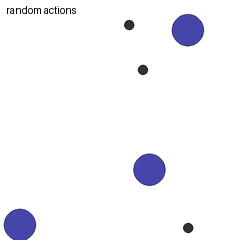

In [3]:
def gif(columns, labels, fps=8):
    """Frames of several episodes side by side, as one small GIF."""
    out = []
    for t in range(min(len(c) for c in columns)):
        panel = Image.fromarray(np.concatenate([c[t] for c in columns], axis=1))
        draw = ImageDraw.Draw(panel)
        width = columns[0][0].shape[1]
        for i, label in enumerate(labels):
            draw.text((i * width + 6, 4), label, fill=(0, 0, 0))
        out.append(panel.quantize(colors=32))
    buffer = BytesIO()
    out[0].save(buffer, format="GIF", save_all=True, append_images=out[1:],
                duration=int(1000 / fps), loop=0, optimize=True)
    return GifImage(data=buffer.getvalue(), format="gif")


frames_random, return_random = episode_frames(ENV_CONFIG, random_policy(ENV_CONFIG, 1), SEED)
print(f"one episode with random actions, return {return_random:.1f}")
gif([frames_random], ["random actions"])

Agents are the large circles, landmarks the small dark ones. Random actions in
[0, 1] give each agent a random push every step, so the agents jitter around the
middle.

## b. Baselines

Two policies to read the training curves against, as episode return summed over the
agents (the metric RLlib reports): **random** (every action element uniform in
[0, 1]) and **zero** (the all-zero action: no force, the agents stay where they
start). Training has to beat both to have learned anything about the task.

Episodes differ a lot: where the landmarks and agents start decides much of the
return (the zero action ranges from about −20 to −110 between episodes). So the
trained policies' mean-action return is compared with the baselines **on the same
evaluation episodes** (right column), not with the 200-episode mean.

In [4]:
baselines = {
    policy: baseline_return(ENV_CONFIG, policy, BASELINE_EPISODES, seed=0)
    for policy in ("random", "zero")
}
# The same episodes the trained policies are evaluated on (section c): episodes
# differ a lot in difficulty, so a few episodes must be compared on the same seeds.
eval_baselines = {
    policy: baseline_return(ENV_CONFIG, policy, EVAL_EPISODES, seed=EVAL_SEED)
    for policy in ("random", "zero")
}
pd.DataFrame(
    {
        f"{BASELINE_EPISODES} episodes": baselines,
        f"evaluation episodes ({EVAL_EPISODES})": eval_baselines,
    }
)

,200 episodes,evaluation episodes (3)
random,-79.68,-52.25
zero,-76.49,-45.74


## c. The 3 x 3 matrix

Every combination of paradigm and algorithm is built with `build_local` (sampling
and learning in this process, no Ray Tune) and trained with `train` for the
iterations in `ITERS`. Per iteration it records the mean episode return of the
sampled episodes (with exploration noise) and the learner's health metrics:

- PPO and APPO: policy **entropy** (should fall as the policy sharpens), **KL**
  between old and new policy, the value function's **explained variance** (PPO
  only), and whether any loss became **NaN**.
- SAC reports no entropy or KL. Recorded instead: the critic's loss (`qf_loss`),
  the temperature `alpha` and the NaN check. SAC and APPO start to learn only after
  enough samples have arrived, so their first iterations have no learner metrics.

After training, the learner's own network plays 20 episodes with the **mean action,
without exploration noise** (`mean_actions`); this is the policy the agents would
act with, and it is what the GIFs in section e show. A combination that cannot be
built or run is recorded as "does not run" with its error.

In [5]:
def health(history: pd.DataFrame) -> dict:
    """Health metrics of one run; None where the algorithm does not report one."""
    def column(name):
        return pd.to_numeric(history[name], errors="coerce").loc[history[name].notna()]

    reported = [column(n) for n in ("policy_loss", "vf_loss", "qf_loss")]
    nan_loss = any((~v.map(math.isfinite)).any() for v in reported if len(v))
    entropy, kl = column("entropy"), column("kl")
    alpha, qf = column("alpha"), column("qf_loss")
    return {
        "nan loss": bool(nan_loss),
        "entropy start": entropy.iloc[0] if len(entropy) else None,
        "entropy end": entropy.iloc[-1] if len(entropy) else None,
        "max kl": kl.max() if len(kl) else None,
        "alpha end": alpha.iloc[-1] if len(alpha) else None,
        "qf_loss end": qf.iloc[-1] if len(qf) else None,
    }


def final_return(history: pd.DataFrame, last: int = 5) -> float:
    """Mean of the last iterations' return (each already a mean over recent episodes)."""
    return float(pd.to_numeric(history.return_mean, errors="coerce").tail(last).mean())


def mean_action_return(algo, trainer, episodes):
    """Mean return of the learner's mean-action policy over fresh episodes."""
    totals = []
    for episode in range(episodes):
        _, total = episode_frames(
            ENV_CONFIG, lambda o: mean_actions(algo, trainer, o), EVAL_SEED + episode, 8
        )
        totals.append(total)
    return float(np.mean(totals))


runs = {}  # (algorithm, paradigm) -> history, health, returns, frames, or error
start_all = time.time()
for algorithm in ALGORITHMS:
    for mode in MODES:
        key = (algorithm.name, mode.value)
        if RUN is not None and key not in RUN:
            runs[key] = dict(error="not selected in RUN")
            continue
        start = time.time()
        try:
            trainer = RLTrainer(
                SimpleSpread, ENV_CONFIG, algorithm, mode,
                iters=1, checkpoint_freq=1, cpus=1, gpus=0,
            )
            algo = build_local(trainer, **TRAINING[algorithm.name])
            try:
                history = train(algo, ITERS[algorithm.name])
                frames, _ = episode_frames(
                    ENV_CONFIG, lambda o: mean_actions(algo, trainer, o), SEED
                )
                det = mean_action_return(algo, trainer, EVAL_EPISODES)
            finally:
                algo.stop()
            learned = history.drop(columns=["return_mean", "seconds"]).notna().any().any()
            runs[key] = dict(history=history, health=health(history), learned=learned,
                             final=final_return(history), det=det, frames=frames)
            print(f"{key[0]:5} {key[1]}: ok, {time.time() - start:5.0f} s, "
                  f"return {runs[key]['final']:7.1f} (sampled), {det:7.1f} (mean action), "
                  f"nan loss {runs[key]['health']['nan loss']}"
                  + ("" if learned else ", NO LEARNER UPDATE YET (raise ITERS)"), flush=True)
        except Exception as error:
            runs[key] = dict(error=f"{type(error).__name__}: {str(error)[:300]}")
            print(f"{key[0]:5} {key[1]}: DOES NOT RUN, {runs[key]['error']}", flush=True)
print(f"total {(time.time() - start_all) / 60:.1f} minutes")

2026-10-12 20:31:30,947	INFO worker.py:2012 -- Started a local Ray instance.
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
2026-10-12 20:31:32,755	WARNING algorithm_config.py:5053 -- You are running PPO on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False,enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be remov

PPO   dtde: ok,    32 s, return   -78.7 (sampled),   -61.3 (mean action), nan loss False


c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

PPO   ctce: ok,    11 s, return   -74.8 (sampled),   -56.2 (mean action), nan loss False


c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
The `JsonLogger interface is deprecated in favor of the `ray.tune.json.JsonLoggerCallback` interface and will be removed in Ray 2.7.
  self._loggers.append(cls(self.config, self.logdir, self.trial))
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be 

...

SAC   dtde: ok,    14 s, return   -78.4 (sampled),   -51.7 (mean action), nan loss False


2026-10-12 20:34:41,497	WARNING sac.py:490 -- You are running SAC on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False, enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\rllib\algorithms\algorithm.py:526: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting env variable PYTHONWARNINGS="ignore::DeprecationWarning"
`UnifiedLogger` will be removed in Ray 2.7.
  return UnifiedLogger(config, logdir, loggers=None)
c:\Users\Kevin\miniconda3\envs\marlem\Lib\site-packages\ray\tune\logger\unified.py:53: RayDeprecationWarning: This API is deprecated and may be removed in future Ray releases. You could suppress this warning by setting 

SAC   ctce: DOES NOT RUN, ValueError: Unsupported action space type: <class 'gymnasium.spaces.dict.Dict'>. Only Discrete and Box action spaces are supported.


2026-10-12 20:34:46,695	WARNING sac.py:490 -- You are running SAC on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False, enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
2026-10-12 20:34:46,827	WARNING sac.py:490 -- You are running SAC on the new API stack! This is the new default behavior for this algorithm. If you don't want to use the new API stack, set `config.api_stack(enable_rl_module_and_learner=False, enable_env_runner_and_connector_v2=False)`. For a detailed migration guide, see here: https://docs.ray.io/en/master/rllib/new-api-stack-migration-guide.html
2026-10-12 20:34:46,936	WARNING util.py:61 -- Install gputil for GPU system monitoring.


SAC   ctde: DOES NOT RUN, ValueError: Unsupported action space type: <class 'gymnasium.spaces.dict.Dict'>. Only Discrete and Box action spaces are supported.
total 3.4 minutes


## d. Results

### Return, compared with the baselines

One cell per combination: the mean of the last five iterations' sampled return
(compare with the 200-episode baselines), and in brackets the return of the
mean-action policy on the evaluation episodes (compare with the baselines on the
same episodes). Higher is better; 0 is the theoretical maximum. A combination whose
learner never updated (SAC and APPO wait for samples first) is marked "no update".

In [6]:
def cell(run):
    if run.get("error") == "not selected in RUN":
        return "not run"
    if "error" in run:
        return "does not run"
    text = f"{run['final']:.1f} ({run['det']:.1f})"
    return text if run["learned"] else text + " no update"


table = pd.DataFrame(
    {a.name: {m.value.upper(): cell(runs[a.name, m.value]) for m in MODES} for a in ALGORITHMS}
)
table.index.name = "paradigm"
print(f"sampled return vs {BASELINE_EPISODES} episodes: random {baselines['random']:.1f}, "
      f"zero {baselines['zero']:.1f}")
print(f"mean action vs the same {EVAL_EPISODES} evaluation episodes: random "
      f"{eval_baselines['random']:.1f}, zero {eval_baselines['zero']:.1f}")
table

sampled return vs 200 episodes: random -79.7, zero -76.5
mean action vs the same 3 evaluation episodes: random -52.2, zero -45.7


,PPO,APPO,SAC
paradigm,,,
DTDE,-78.7 (-61.3),-76.3 (-57.6),-78.4 (-51.7)
CTCE,-74.8 (-56.2),-79.3 (-55.3),does not run
CTDE,-77.7 (-53.8),-77.7 (-48.5),does not run


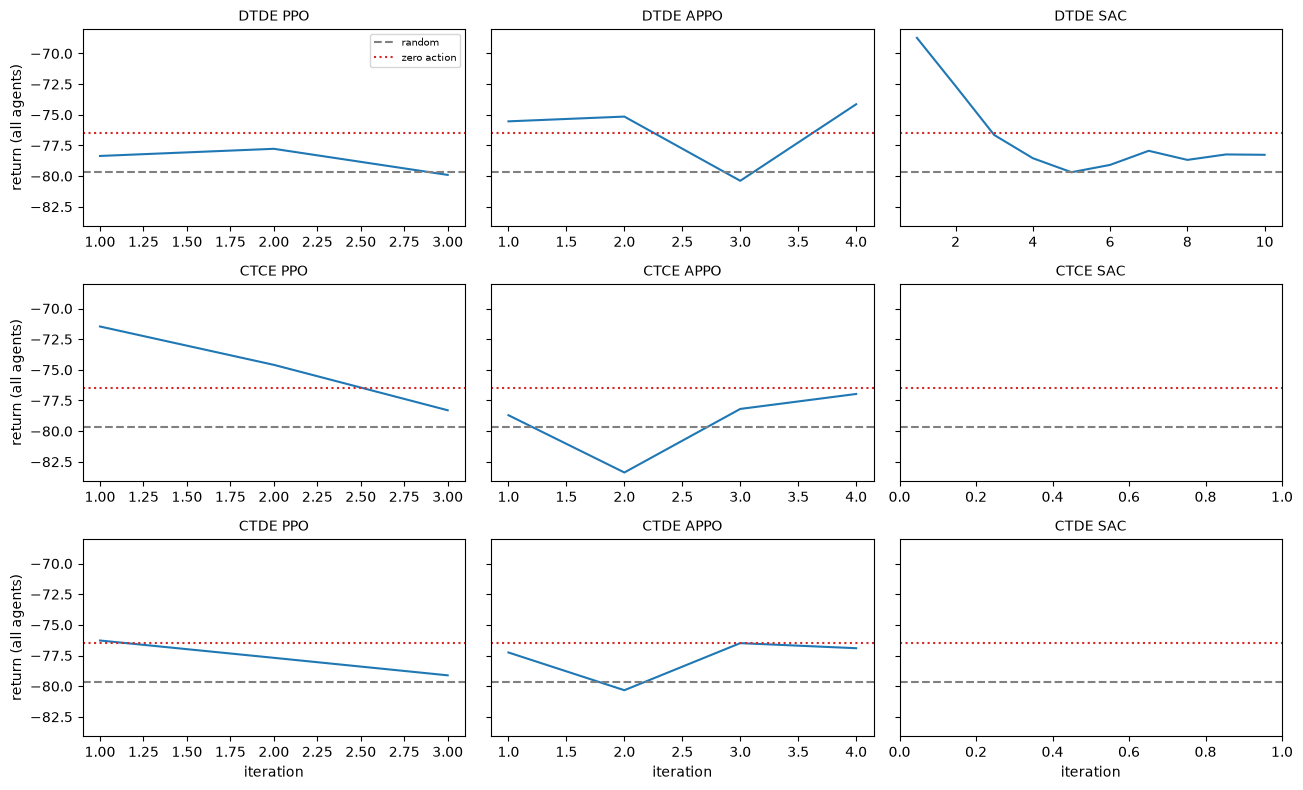

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharey=True)
for row, mode in enumerate(MODES):
    for col, algorithm in enumerate(ALGORITHMS):
        ax, run = axes[row, col], runs[algorithm.name, mode.value]
        if "error" not in run:
            ax.plot(run["history"].index, run["history"].return_mean)
        ax.axhline(baselines["random"], color="grey", ls="--", label="random")
        ax.axhline(baselines["zero"], color="tab:red", ls=":", label="zero action")
        ax.set_title(f"{mode.value.upper()} {algorithm.name}", fontsize=10)
        if row == 2:
            ax.set_xlabel("iteration")
        if col == 0:
            ax.set_ylabel("return (all agents)")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### Learner health

Entropy and KL for PPO and APPO, the temperature for SAC; one line per paradigm.
The table lists every run. A NaN loss, or an entropy that grows instead of
falling, is a learner problem, whatever the return does.

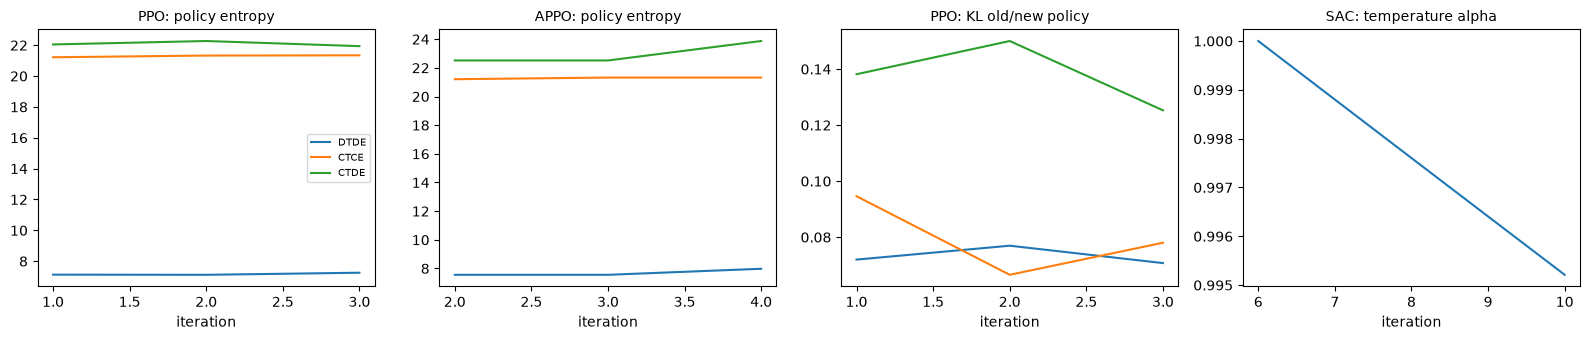

nan loss entropy start entropy end max kl alpha end qf_loss end
algorithm paradigm                                                                
PPO       dtde        False          7.13        7.25   0.08      None        None
          ctce        False         21.22       21.34   0.09      None        None
          ctde        False         22.05       21.94   0.15      None        None
APPO      dtde        False          7.56        7.98    0.0      None        None
          ctce        False         21.21       21.32    0.0      None        None
          ctde        False         22.52       23.87    0.0      None        None
SAC       dtde        False          None        None   None       1.0        0.86

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
panels = [("PPO", "entropy", "PPO: policy entropy"), ("APPO", "entropy", "APPO: policy entropy"),
          ("PPO", "kl", "PPO: KL old/new policy"), ("SAC", "alpha", "SAC: temperature alpha")]
for ax, (algorithm, column, title) in zip(axes, panels):
    for mode in MODES:
        run = runs[algorithm, mode.value]
        if "error" in run:
            continue
        values = pd.to_numeric(run["history"][column], errors="coerce")
        ax.plot(values.index, values, label=mode.value.upper())
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("iteration")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

health_table = pd.DataFrame({k: r["health"] for k, r in runs.items() if "error" not in r}).T
health_table.index.names = ["algorithm", "paradigm"]
health_table

### How to read this

What to expect, given what the probes showed (`probe_paradigms.ipynb`):

- **Random and zero-action returns** are the floor. A combination near them has not
  learned the task; a clearly higher return has. Both are noisy: the baselines are
  means over 200 episodes, the curves over the episodes of one iteration.
- **DTDE** (one network per agent) worked in the probes, so it is the combination
  that should improve first. It still gets little experience here (see `ITERS`);
  `simple_spread` usually needs far more than the 60,000 steps used here, so a flat
  curve after this budget is not yet a failure.
- **CTDE** trains a central actor and critic, but the heads that act (`pi_heads`)
  are never trained, so its acting policy should stay at its random start: expect
  its return not to improve, whatever its training losses do.
- **CTCE and CTDE** have an unbounded log-std in the action distribution (it was
  seen to diverge to NaN in the probes). Look for an entropy that grows without
  limit and for NaN losses in the health table.
- **SAC with CTCE or CTDE does not run.** The grouped paradigms give each group a
  `Dict` action space, and RLlib's SAC learner (Ray 2.51.1, the version the
  original pins in `environment.yml`) accepts only `Box` and `Discrete`: the first
  learning update raises `ValueError: Unsupported action space type`. Salazar's
  modules implement SAC's networks, but RLlib never gets as far as calling them. So
  the original cannot train SAC-CTCE or SAC-CTDE at its own pinned versions.
- **APPO** had not been run on this branch before the quick tests; it runs in all
  three paradigms. SAC with the original's replay buffer of 1,000
  steps has a short memory.
- The return in brackets is the policy without exploration noise. If it is far
  from the sampled return, the noise (not the mean) is deciding the result.

## e. Watching the agents

The same episode (same start positions) played by random actions and by the trained
policies' mean actions. Agents that learned to spread each move to a different
landmark and stay there; agents that did not look like the random ones, or stand
still. The first GIF is DTDE-PPO, the combination the probes trust most; the second
is the combination with the best mean-action return, when it is a different one.

DTDE PPO, mean action over 3 episodes: -61.3; zero action on the same episodes -45.7


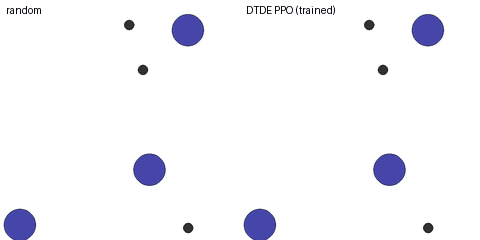

In [9]:
frames_random, _ = episode_frames(ENV_CONFIG, random_policy(ENV_CONFIG, 1), SEED)
dtde_ppo = runs["PPO", "dtde"]
if "error" in dtde_ppo:
    print("DTDE PPO does not run:", dtde_ppo["error"])
else:
    print(f"DTDE PPO, mean action over {EVAL_EPISODES} episodes: {dtde_ppo['det']:.1f}; "
          f"zero action on the same episodes {eval_baselines['zero']:.1f}")
    display(gif([frames_random, dtde_ppo["frames"]], ["random", "DTDE PPO (trained)"]))

best mean-action return: APPO CTDE, -48.5


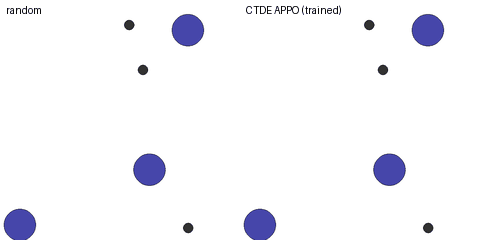

In [10]:
ran = {k: r for k, r in runs.items() if "error" not in r}
if not ran:
    raise SystemExit("no combination ran")
best = max(ran, key=lambda k: ran[k]["det"])
print(f"best mean-action return: {best[0]} {best[1].upper()}, {ran[best]['det']:.1f}")
if best != ("PPO", "dtde"):
    display(gif([frames_random, ran[best]["frames"]],
                ["random", f"{best[1].upper()} {best[0]} (trained)"]))
else:
    print("same as the GIF above")